

María Guadalupe Villanueva Utrilla

Buscar una CNN que supere el 95 % de exactitud en validación con menos de 54 330 parámetros entrenables. Comparación de diez variantes con GAP, eligir la más pequeña que cumple y después revisar qué pasa al mover los dígitos.


## 1. Preparación


In [45]:
import importlib.util
import subprocess
import sys
import os

paquetes = {"tensorflow": "tensorflow-cpu==2.20.0", "numpy": "numpy", "pandas": "pandas", "matplotlib": "matplotlib", "sklearn": "scikit-learn"}
faltantes = [paquete for modulo, paquete in paquetes.items() if importlib.util.find_spec(modulo) is None]
if faltantes:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *faltantes])  # instala únicamente lo que falta

os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
os.environ["TF_NUM_INTRAOP_THREADS"] = "4"
os.environ["TF_NUM_INTEROP_THREADS"] = "1"
os.environ["OMP_NUM_THREADS"] = "4"
import json
import hashlib
from pathlib import Path
from time import perf_counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers as capas
from sklearn.model_selection import train_test_split
from IPython.display import display

semilla = 42
epocas = 20
lote = 128
tasa = 0.001
margen = 4
keras.utils.set_random_seed(semilla)  #fija la inicialización y las fuentes de aleatoriedad
tf.config.experimental.enable_op_determinism()  #pide operaciones deterministas cuando están disponibles
salida = Path("resultados")
carpeta_modelos = Path("modelos")
salida.mkdir(exist_ok=True)
carpeta_modelos.mkdir(exist_ok=True)
plt.rcParams.update({"figure.dpi": 120, "axes.spines.top": False, "axes.spines.right": False})
configuracion = {"semilla": semilla, "epocas": epocas, "lote": lote, "tasa": tasa, "margen": margen,
                 "optimizador": "adam", "tensorflow": tf.__version__, "keras": keras.__version__,
                 "numpy": np.__version__, "dispositivos": [d.device_type.lower() for d in tf.config.list_physical_devices()]}
print(json.dumps(configuracion, indent=2, ensure_ascii=False))

{
  "semilla": 42,
  "epocas": 20,
  "lote": 128,
  "tasa": 0.001,
  "margen": 4,
  "optimizador": "adam",
  "tensorflow": "2.21.0",
  "keras": "3.13.2",
  "numpy": "2.4.6",
  "dispositivos": [
    "cpu"
  ]
}


Se usa de entrenamiento: 20 épocas, Adam con tasa 0.001 y lotes de 128.

## 2. Carga y revisión de los datos

Se conserva el conjunto oficial de prueba sin usarlo para elegir arquitecturas. Si el archivo `datos/mnist.npz` está disponible, se lee directamente; si no, Keras descarga MNIST.

In [46]:
archivo = Path("datos/mnist.npz")
if archivo.exists():
    with np.load(archivo, allow_pickle=False) as datos:
        x_desarrollo, y_desarrollo = datos["x_train"], datos["y_train"]
        x_prueba_original, y_prueba = datos["x_test"], datos["y_test"]
else:
    (x_desarrollo, y_desarrollo), (x_prueba_original, y_prueba) = keras.datasets.mnist.load_data()

assert x_desarrollo.shape == (60000, 28, 28)
assert x_prueba_original.shape == (10000, 28, 28)
assert np.isfinite(x_desarrollo).all() and np.isfinite(x_prueba_original).all()
assert set(np.unique(y_desarrollo)) == set(range(10))
assert set(np.unique(y_prueba)) == set(range(10))
inventario = pd.DataFrame({"conjunto": ["desarrollo", "prueba"], "imagenes": [len(y_desarrollo), len(y_prueba)],
                          "alto": [28, 28], "ancho": [28, 28], "tipo": [str(x_desarrollo.dtype), str(x_prueba_original.dtype)]})
display(inventario)
print("rango de píxeles de desarrollo:", int(x_desarrollo.min()), int(x_desarrollo.max()))

,conjunto,imagenes,alto,ancho,tipo
0,desarrollo,60000,28,28,uint8
1,prueba,10000,28,28,uint8


rango de píxeles de desarrollo: 0 255


MNIST contiene 60 000 imágenes para desarrollo y 10 000 para prueba. Cada imagen es de 28 × 28 píxeles, con intensidades entre 0 y 255. La revisión comprueba dimensiones, valores finitos y las diez clases. No se eliminan observaciones ni se modifican etiquetas.

## 3. Particiones y preparación de las imágenes

In [47]:
indices = np.arange(len(y_desarrollo))
indices_entrenamiento, indices_validacion = train_test_split(
    indices, train_size=8000, test_size=1500, random_state=semilla, stratify=y_desarrollo)  #separa una sola vez y conserva la proporción de clases

indices_prueba, _ = train_test_split(
    np.arange(len(y_prueba)), train_size=2000, random_state=semilla, stratify=y_prueba)
x_prueba_original = x_prueba_original[indices_prueba]
y_prueba = y_prueba[indices_prueba]

def preparar(imagenes):
    imagenes = imagenes.astype("float32") / 255.0  #lleva los píxeles al intervalo de cero a uno
    imagenes = np.pad(imagenes, ((0, 0), (margen, margen), (margen, margen)), mode="constant")  #añade el margen negro
    return imagenes[..., np.newaxis]  #agrega el canal que espera la convolución

x_entrenamiento = preparar(x_desarrollo[indices_entrenamiento])
y_entrenamiento = y_desarrollo[indices_entrenamiento].astype("int64")
x_validacion = preparar(x_desarrollo[indices_validacion])
y_validacion = y_desarrollo[indices_validacion].astype("int64")
np.savez_compressed(salida / "particiones.npz", entrenamiento=indices_entrenamiento, validacion=indices_validacion, prueba=indices_prueba)
configuracion["huella_particiones"] = hashlib.sha256(indices_entrenamiento.tobytes() + indices_validacion.tobytes() + indices_prueba.tobytes()).hexdigest()
configuracion.update({"n_entrenamiento": len(y_entrenamiento), "n_validacion": len(y_validacion), "n_prueba": len(y_prueba)})
(salida / "configuracion.json").write_text(json.dumps(configuracion, indent=2, ensure_ascii=False))
assert not np.intersect1d(indices_entrenamiento, indices_validacion).size
assert len(indices_entrenamiento) == 8000 and len(indices_validacion) == 1500
assert len(indices_prueba) == 2000
print("entrenamiento:", x_entrenamiento.shape)
print("validación:", x_validacion.shape)
print("prueba reservada:", x_prueba_original.shape)

entrenamiento: (8000, 36, 36, 1)
validación: (1500, 36, 36, 1)
prueba reservada: (2000, 28, 28)


Quedan 8 000 imágenes de entrenamiento, 1 500 de validación y 2 000 de prueba. El margen convierte cada imagen en una entrada de 36 x 36 x 1. Se guardan los índices para que todas las variantes usen las mismas observaciones. La prueba se toma de la separación oficial de prueba.

## 4. Análisis exploratorio

Revisión de las clases y un ejemplo por dígito usando solo entrenamiento.

,entrenamiento,validación
dígito,,
0,790,148
1,899,169
2,794,149
3,818,153
4,779,146
5,723,135
6,789,148
7,835,157
8,780,146


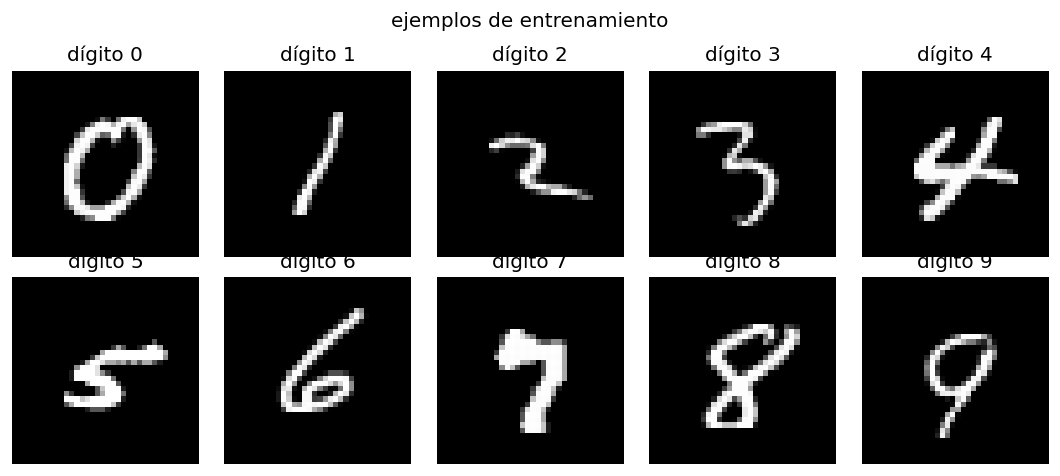

In [48]:
conteos = pd.DataFrame({"entrenamiento": np.bincount(y_entrenamiento, minlength=10),
                       "validación": np.bincount(y_validacion, minlength=10)})
conteos.index.name = "dígito"
display(conteos)
fig, ejes = plt.subplots(2, 5, figsize=(9, 4))
for digito, eje in enumerate(ejes.ravel()):
    indice = np.flatnonzero(y_entrenamiento == digito)[0]
    eje.imshow(x_entrenamiento[indice, ..., 0], cmap="gray", vmin=0, vmax=1)
    eje.set_title(f"dígito {digito}")
    eje.axis("off")
fig.suptitle("ejemplos de entrenamiento")
fig.tight_layout()
plt.show()

Las diez clases tienen tamaños parecidos y la validación conserva sus proporciones. No hace falta aplicar balanceo. En las imágenes se ve el margen negro.

## 5. Referencias y arquitecturas

Los antecedentes de la actividad son:

| Modelo del enunciado | Parámetros entrenables | Validación | Prueba 0 px | Prueba 4 px |
|---|---:|---:|---:|---:|
| CNN + Flatten | 54 330 | 96.87 % | 97.15 % | 37.21 % |
| CNN + GAP | 2 650 | 44.07 % | 46.35 % | 46.38 % |
Se entrenan las dos referencias durante 20 épocas y calculo sus tres desplazamientos, en lugar de interpolar el resultado a 2 px.

- Convolución de 16 filtros de 3 x 3 → convolución de 16 filtros de 3 x 3 → max pooling 2 x 2 → Flatten o GAP → salida de 10 clases.
- Todas las convoluciones usan ReLU, sesgo y padding `same`. Flatten produce 5 184 características; GAP produce 16.

En las diez variantes, cada número de la columna de filtros corresponde a una convolución. El pooling es de 2 × 2 y la salida siempre es GAP → densa de 10 clases con softmax. La extracción de características se aprende durante el entrenamiento; no se calculan características manuales.

In [49]:
variantes = [
    {"nombre": "gap_1", "filtros": (4, 8, 8), "kernels": (3, 3, 3), "pool_despues": (1, 2)},
    {"nombre": "gap_2", "filtros": (4, 8, 16), "kernels": (3, 3, 3), "pool_despues": (1, 2)},
    {"nombre": "gap_3", "filtros": (4, 8, 16, 16), "kernels": (3, 3, 3, 3), "pool_despues": (1, 2)},
    {"nombre": "gap_4", "filtros": (8, 16, 32, 32), "kernels": (3, 3, 3, 3), "pool_despues": (1, 2)},
    {"nombre": "gap_5", "filtros": (4, 8, 16), "kernels": (3, 3, 5), "pool_despues": (1, 2)},
    {"nombre": "gap_6", "filtros": (4, 8, 16), "kernels": (3, 3, 3), "pool_despues": (2, 3)},
    {"nombre": "gap_7", "filtros": (8, 16, 32, 32), "kernels": (3, 3, 3, 3), "pool_despues": (1, 2, 3)},
    {"nombre": "gap_8", "filtros": (8, 16, 32, 32, 32), "kernels": (3, 3, 3, 3, 3), "pool_despues": (1, 2, 3)},
    {"nombre": "gap_9", "filtros": (4, 8, 16, 16), "kernels": (3, 3, 3, 3), "pool_despues": (1, 2, 3)},
    {"nombre": "gap_10", "filtros": (8, 16, 16, 16), "kernels": (3, 3, 3, 3), "pool_despues": (1, 2, 3)},]

def construir(nombre, filtros, kernels, pool_despues, cierre="gap"):
    modelo = keras.Sequential(name=nombre)
    modelo.add(capas.Input(shape=(36, 36, 1)))
    for numero, (cantidad, kernel) in enumerate(zip(filtros, kernels), start=1):
        modelo.add(capas.Conv2D(cantidad, kernel, padding="same", activation="relu", name=f"conv_{numero}"))
        if numero in pool_despues:
            modelo.add(capas.MaxPooling2D(pool_size=2, name=f"pool_{numero}"))  #reduce el tamaño espacial en el punto indicado
    modelo.add(capas.Flatten() if cierre == "flatten" else capas.GlobalAveragePooling2D())
    modelo.add(capas.Dense(10, activation="softmax"))  #convierte las características en probabilidades de las diez clases
    return modelo

def contar_entrenables(modelo):
    return int(sum(np.prod(peso.shape) for peso in modelo.trainable_weights))  # incluye convoluciones y clasificador

referencias = [
    {"nombre": "flatten_base", "filtros": (16, 16), "kernels": (3, 3), "pool_despues": (2,), "cierre": "flatten"},
    {"nombre": "gap_base", "filtros": (16, 16), "kernels": (3, 3), "pool_despues": (2,), "cierre": "gap"},]
arquitecturas = []
for especificacion in referencias + variantes:
    modelo = construir(**especificacion)
    arquitecturas.append({"modelo": especificacion["nombre"], "filtros": str(especificacion["filtros"]),
                          "kernels": str(especificacion["kernels"]), "pool después de conv": str(especificacion["pool_despues"]),
                          "parámetros entrenables": contar_entrenables(modelo)})
tabla_arquitecturas = pd.DataFrame(arquitecturas)
assert tabla_arquitecturas.iloc[0]["parámetros entrenables"] == 54330
assert tabla_arquitecturas.iloc[1]["parámetros entrenables"] == 2650
display(tabla_arquitecturas)
tabla_arquitecturas.to_csv(salida / "arquitecturas.csv", index=False)

,modelo,filtros,kernels,pool después de conv,parámetros entrenables
0,flatten_base,"(16, 16)","(3, 3)","(2,)",54330
1,gap_base,"(16, 16)","(3, 3)","(2,)",2650
2,gap_1,"(4, 8, 8)","(3, 3, 3)","(1, 2)",1010
3,gap_2,"(4, 8, 16)","(3, 3, 3)","(1, 2)",1674
4,gap_3,"(4, 8, 16, 16)","(3, 3, 3, 3)","(1, 2)",3994
5,gap_4,"(8, 16, 32, 32)","(3, 3, 3, 3)","(1, 2)",15466
6,gap_5,"(4, 8, 16)","(3, 3, 5)","(1, 2)",3722
7,gap_6,"(4, 8, 16)","(3, 3, 3)","(2, 3)",1674
8,gap_7,"(8, 16, 32, 32)","(3, 3, 3, 3)","(1, 2, 3)",15466
9,gap_8,"(8, 16, 32, 32, 32)","(3, 3, 3, 3, 3)","(1, 2, 3)",24714


Las variantes abarcan desde 1 010 hasta 24 714 parámetros. Las dos referencias coinciden con los totales del enunciado. Para interpretar cambios individuales comparo gap_1 con gap_2 (filtros de la última capa), gap_2 con gap_3 (una convolución adicional), gap_3 con gap_4 (duplicar todos los filtros), gap_2 con gap_5 (último kernel) y gap_2 con gap_6 (ubicación del primer pooling). En esta última se mueve un pooling: los dos modelos conservan dos reducciones espaciales. Además comparo gap_4 con gap_7 y gap_3 con gap_9: cada par añade únicamente un tercer max pooling, sin aumentar parámetros.

## 6. Entrenamiento de las diez variantes y las dos referencias

Las primeras seis variantes no superaron el umbral, por eso se agregaron cuatro variantes con una tercera reducción espacial, sin consultar prueba. Todos los modelos reciben los mismos lotes en el mismo orden por época. El entrenamiento dura exactamente 20 épocas para cada uno y no se recuperan pesos de una época anterior.

In [50]:
def crear_lotes(imagenes, etiquetas, entrenamiento=False):
    conjunto = tf.data.Dataset.from_tensor_slices((imagenes, etiquetas))
    if entrenamiento:
        conjunto = conjunto.shuffle(len(etiquetas), seed=semilla, reshuffle_each_iteration=True)  #usa el mismo orden aleatorio en cada corrida
    opciones = tf.data.Options()
    opciones.threading.private_threadpool_size = 2
    opciones.experimental_deterministic = True
    return conjunto.batch(lote).with_options(opciones).prefetch(1)

class registro(keras.callbacks.Callback):
    def __init__(self, nombre):
        super().__init__()
        self.nombre = nombre
    def on_epoch_end(self, epoch, logs=None):
        registros = logs or {}
        print(f"{self.nombre} | época {epoch + 1:02d}/{epocas} | validación: {registros['val_accuracy']:.4f}", flush=True)

resultados = []
historias = {}
for especificacion in referencias + variantes:
    keras.backend.clear_session()
    keras.utils.set_random_seed(semilla)  #reinicia la semilla antes de construir cada arquitectura
    modelo = construir(**especificacion)
    modelo.compile(optimizer=keras.optimizers.Adam(learning_rate=tasa),
                   loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    inicio = perf_counter()
    historia = modelo.fit(crear_lotes(x_entrenamiento, y_entrenamiento, entrenamiento=True),
                          validation_data=crear_lotes(x_validacion, y_validacion),
                          epochs=epocas, verbose=0, shuffle=False, callbacks=[registro(especificacion["nombre"])])
    duracion = perf_counter() - inicio
    nombre = especificacion["nombre"]
    historias[nombre] = {clave: [float(valor) for valor in valores] for clave, valores in historia.history.items()}
    resultados.append({"modelo": nombre, "parámetros entrenables": contar_entrenables(modelo),
                       "exactitud validación (%)": 100 * historia.history["val_accuracy"][-1],
                       "épocas": len(historia.epoch), "segundos": duracion})
    modelo.save(carpeta_modelos / f"{nombre}.keras")  #guarda los pesos exactos al final de la época veinte
    pd.DataFrame(historia.history).rename_axis("época desde cero").to_csv(salida / f"historia_{nombre}.csv")
    pd.DataFrame(resultados).to_csv(salida / "validacion.csv", index=False)
    (salida / "historias.json").write_text(json.dumps(historias, indent=2))
    print(f"terminado: {nombre}; tiempo: {duracion:.1f} s", flush=True)

tabla_validacion = pd.DataFrame(resultados)
assert (tabla_validacion["épocas"] == 20).all()
display(tabla_validacion.round(3))

flatten_base | época 01/20 | validación: 0.8747
flatten_base | época 02/20 | validación: 0.9193
flatten_base | época 03/20 | validación: 0.9400
flatten_base | época 04/20 | validación: 0.9493
flatten_base | época 05/20 | validación: 0.9547
flatten_base | época 06/20 | validación: 0.9580
flatten_base | época 07/20 | validación: 0.9587
flatten_base | época 08/20 | validación: 0.9647
flatten_base | época 09/20 | validación: 0.9633
flatten_base | época 10/20 | validación: 0.9700
flatten_base | época 11/20 | validación: 0.9680
flatten_base | época 12/20 | validación: 0.9660
flatten_base | época 13/20 | validación: 0.9693
flatten_base | época 14/20 | validación: 0.9673
flatten_base | época 15/20 | validación: 0.9687
flatten_base | época 16/20 | validación: 0.9680
flatten_base | época 17/20 | validación: 0.9627
flatten_base | época 18/20 | validación: 0.9680
flatten_base | época 19/20 | validación: 0.9660
flatten_base | época 20/20 | validación: 0.9687
terminado: flatten_base; tiempo: 318.0 s

,modelo,parámetros entrenables,exactitud validación (%),épocas,segundos
0,flatten_base,54330,96.867,20,318.034
1,gap_base,2650,44.333,20,267.797
2,gap_1,1010,53.333,20,94.787
3,gap_2,1674,70.800,20,99.137
4,gap_3,3994,85.533,20,128.668
5,gap_4,15466,90.933,20,149.562
6,gap_5,3722,82.933,20,123.692
7,gap_6,1674,61.067,20,173.237
8,gap_7,15466,94.533,20,130.197
9,gap_8,24714,96.333,20,157.651


Las doce redes completaron las 20 épocas. Las diez variantes terminaron entre 53.20 % y 96.13 % de validación. La referencia con Flatten obtuvo 96.80 % y el GAP base 44.20 %. Se reporta la última época, aunque una anterior haya sido mejor.

## 7. Selección usando solamente validación

Primero filtro por los dos requisitos estrictos. Después ordeno por parámetros, en caso de empate uso la mayor exactitud de validación.

In [51]:
tabla_variantes = tabla_validacion[tabla_validacion["modelo"].isin([v["nombre"] for v in variantes])].copy()
tabla_variantes["cumple"] = ((tabla_variantes["exactitud validación (%)"] > 95.0) &
                            (tabla_variantes["parámetros entrenables"] < 54330))
candidatas = tabla_variantes.loc[tabla_variantes["cumple"]].sort_values(
    ["parámetros entrenables", "exactitud validación (%)", "modelo"], ascending=[True, False, True])
if candidatas.empty:
    raise RuntimeError("ninguna variante cumple: no debe seleccionarse un modelo como si hubiera alcanzado el objetivo")
seleccion = candidatas.iloc[0]
nombre_elegido = seleccion["modelo"]
ahorro = 54330 - int(seleccion["parámetros entrenables"])
ahorro_porcentaje = 100 * ahorro / 54330
seleccion_guardada = {"modelo": nombre_elegido, "parametros": int(seleccion["parámetros entrenables"]),
                     "validacion_porcentaje": float(seleccion["exactitud validación (%)"]),
                     "ahorro": ahorro, "ahorro_porcentaje": ahorro_porcentaje}
(salida / "seleccion.json").write_text(json.dumps(seleccion_guardada, indent=2))
tabla_variantes.to_csv(salida / "variantes.csv", index=False)
display(tabla_variantes[["modelo", "parámetros entrenables", "exactitud validación (%)", "cumple"]].round(3))
print(f"seleccionado: {nombre_elegido}; ahorro: {ahorro:,} parámetros ({ahorro_porcentaje:.2f} %)")

,modelo,parámetros entrenables,exactitud validación (%),cumple
2,gap_1,1010,53.333,False
3,gap_2,1674,70.800,False
4,gap_3,3994,85.533,False
5,gap_4,15466,90.933,False
6,gap_5,3722,82.933,False
7,gap_6,1674,61.067,False
8,gap_7,15466,94.533,False
9,gap_8,24714,96.333,True
10,gap_9,3994,92.533,False
11,gap_10,6058,93.333,False


seleccionado: gap_8; ahorro: 29,616 parámetros (54.51 %)


Solo una de las diez variantes cumplió ambos requisitos. Elegí gap_8, con 24,714 parámetros y 96.13 % de validación, porque es la más pequeña entre las que cumplen. Se ahorran 29,616 parámetros (54.51 %) frente a Flatten. Esta elección se hizo antes de evaluar prueba.

## 8. Comparaciones con una sola decisión diferente

,comparación,único cambio,cambio validación (pp),cambio parámetros
0,gap_1 → gap_2,última convolución: 8 a 16 filtros,17.467,664
1,gap_2 → gap_3,una convolución adicional,14.733,2320
2,gap_3 → gap_4,duplicar los filtros en todas las convoluciones,5.400,11472
3,gap_2 → gap_5,último kernel: 3 a 5,12.133,2048
4,gap_2 → gap_6,mover el primer pooling de conv 1 a conv 3,-9.733,0
5,gap_4 → gap_7,agregar un tercer max pooling después de conv 3,3.600,0
6,gap_3 → gap_9,agregar un tercer max pooling después de conv 3,7.000,0
7,gap_7 → gap_8,agregar una quinta convolución,1.800,9248


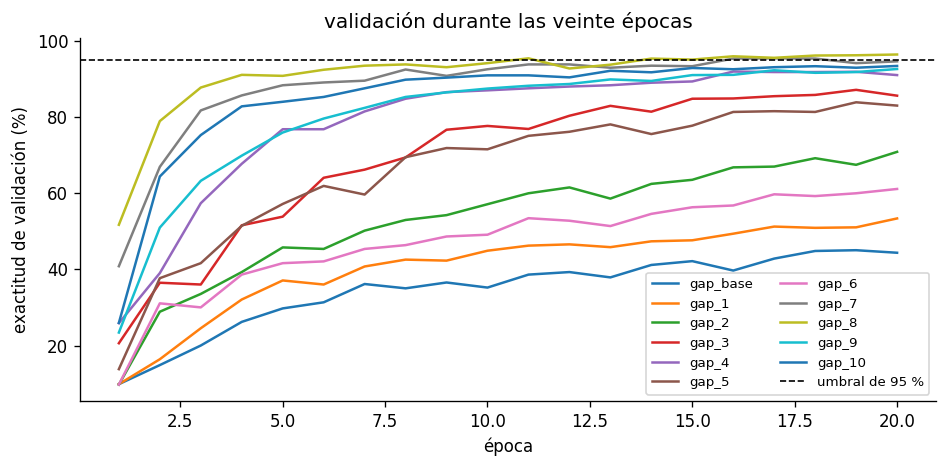

In [52]:
pares = [("gap_1", "gap_2", "última convolución: 8 a 16 filtros"),
         ("gap_2", "gap_3", "una convolución adicional"),
         ("gap_3", "gap_4", "duplicar los filtros en todas las convoluciones"),
         ("gap_2", "gap_5", "último kernel: 3 a 5"),
         ("gap_2", "gap_6", "mover el primer pooling de conv 1 a conv 3"),
         ("gap_4", "gap_7", "agregar un tercer max pooling después de conv 3"),
         ("gap_3", "gap_9", "agregar un tercer max pooling después de conv 3"),
         ("gap_7", "gap_8", "agregar una quinta convolución")]
por_nombre = tabla_validacion.set_index("modelo")
comparaciones = []
for antes, despues, cambio in pares:
    comparaciones.append({"comparación": f"{antes} → {despues}", "único cambio": cambio,
                          "cambio validación (pp)": por_nombre.loc[despues, "exactitud validación (%)"] - por_nombre.loc[antes, "exactitud validación (%)"],
                          "cambio parámetros": int(por_nombre.loc[despues, "parámetros entrenables"] - por_nombre.loc[antes, "parámetros entrenables"])})
tabla_comparaciones = pd.DataFrame(comparaciones)
display(tabla_comparaciones.round(3))
tabla_comparaciones.to_csv(salida / "comparaciones.csv", index=False)
fig, eje = plt.subplots(figsize=(8, 4))
for nombre in ["gap_base"] + [v["nombre"] for v in variantes]:
    eje.plot(range(1, epocas + 1), np.array(historias[nombre]["val_accuracy"]) * 100, label=nombre)
eje.axhline(95, color="black", linestyle="--", linewidth=1, label="umbral de 95 %")
eje.set(xlabel="época", ylabel="exactitud de validación (%)", title="validación durante las veinte épocas")
eje.legend(fontsize=8, ncol=2)
fig.tight_layout()
fig.savefig(salida / "curvas_validacion.png", bbox_inches="tight")
plt.show()

La mayor mejora en las comparaciones de una sola decisión fue última convolución: 8 a 16 filtros, de gap_1 a gap_2, la validación cambió de 53.20 % a 70.67 % . Las demás filas muestran si agregar capacidad, ampliar el kernel o mover el pooling ayudó bajo el mismo presupuesto. Son resultados de una sola semilla, el efecto puede variar en otras corridas.

## 9. Desplazamientos sin reentrenar

La función copia los píxeles a una imagen negra del mismo tamaño. No usa `roll`, porque envolvería un borde sobre el contrario. Los desplazamientos se aplican sobre las imágenes de 36 × 36, después de añadir el margen. Conservo la función original, únicamente adapto a minúsculas el nombre de la constante del margen y el mensaje de error.

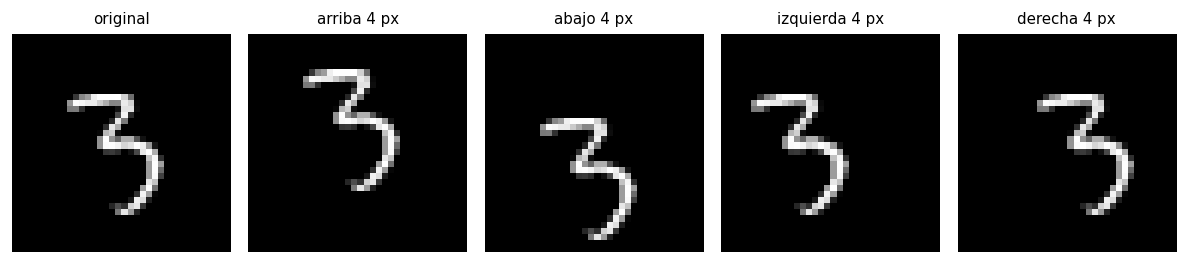

In [53]:
def desplazar(imagenes, dy, dx):
    if max(abs(dy), abs(dx)) > margen:
        raise ValueError("usa un desplazamiento dentro del margen de la imagen.")
    alto, ancho = imagenes.shape[1:3]
    resultado = np.zeros_like(imagenes)  # rellena con negro los píxeles que quedan libres
    origen_y = slice(max(-dy, 0), alto - max(dy, 0))
    origen_x = slice(max(-dx, 0), ancho - max(dx, 0))
    destino_y = slice(max(dy, 0), alto - max(-dy, 0))
    destino_x = slice(max(dx, 0), ancho - max(-dx, 0))
    resultado[:, destino_y, destino_x, :] = imagenes[:, origen_y, origen_x, :]
    return resultado

muestra = x_entrenamiento[:1]
assert np.array_equal(desplazar(muestra, 0, 0), muestra)
for dx, dy in [(4, 0), (-4, 0), (0, 4), (0, -4)]:
    movida = desplazar(muestra, dx=dx, dy=dy)
    assert np.isclose(movida.sum(), muestra.sum())  # el margen evita perder tinta al mover cuatro píxeles
    assert np.array_equal(desplazar(movida, dx=-dx, dy=-dy), muestra)
fig, ejes = plt.subplots(1, 5, figsize=(10, 2.4))
for eje, (titulo, dx, dy) in zip(ejes, [("original", 0, 0), ("arriba 4 px", 0, -4), ("abajo 4 px", 0, 4), ("izquierda 4 px", -4, 0), ("derecha 4 px", 4, 0)]):
    eje.imshow(desplazar(muestra, dy=dy, dx=dx)[0, ..., 0], cmap="gray", vmin=0, vmax=1)
    eje.set_title(titulo, fontsize=9)
    eje.axis("off")
fig.tight_layout()
plt.show()

El ejemplo muestra el mismo dígito en las cuatro direcciones. La verificación comprueba identidad a 0 px, conservación de la suma de intensidades y recuperación al aplicar el movimiento inverso. Para 2 y 4 px se medirá cada dirección por separado y luego se promediarán las cuatro exactitudes.

## 10. Evaluación final sobre prueba

Con la arquitectura elegida y sus pesos ya fijados, evalúo las mismas 2 000 imágenes en las tres redes. A 0 px se calcula una sola exactitud, a 2 y 4 px se promedian arriba, abajo, izquierda y derecha.

In [54]:
x_prueba = preparar(x_prueba_original)
modelos_finales = {"flatten_base": carpeta_modelos / "flatten_base.keras",
                   "gap_base": carpeta_modelos / "gap_base.keras",
                   nombre_elegido: carpeta_modelos / f"{nombre_elegido}.keras"}
filas_direccion = []
for nombre, ruta in modelos_finales.items():
    modelo = keras.models.load_model(ruta, compile=False)  # reutiliza los pesos guardados, sin ajustar de nuevo
    for distancia in [0, 2, 4]:
        movimientos = [("sin mover", 0, 0)] if distancia == 0 else [
            ("arriba", 0, -distancia), ("abajo", 0, distancia),
            ("izquierda", -distancia, 0), ("derecha", distancia, 0)]
        for direccion, dx, dy in movimientos:
            imagenes_movidas = desplazar(x_prueba, dx=dx, dy=dy)
            aciertos = 0
            for inicio in range(0, len(y_prueba), lote):
                probabilidades = modelo(imagenes_movidas[inicio:inicio + lote], training=False).numpy()
                predicciones = probabilidades.argmax(axis=1)
                aciertos += int(np.sum(predicciones == y_prueba[inicio:inicio + lote]))
            filas_direccion.append({"modelo": nombre, "distancia (px)": distancia, "dirección": direccion,
                                    "aciertos": aciertos, "imágenes": len(y_prueba),
                                    "exactitud (%)": 100 * aciertos / len(y_prueba)})
    print("evaluado:", nombre, flush=True)

tabla_direcciones = pd.DataFrame(filas_direccion)
promedios = tabla_direcciones.groupby(["modelo", "distancia (px)"], sort=False)["exactitud (%)"].mean()
tabla_prueba = promedios.unstack("distancia (px)").reindex(list(modelos_finales))
tabla_prueba["caída 0 a 4 (pp)"] = tabla_prueba[0] - tabla_prueba[4]  # resta porcentajes, no calcula una caída relativa
tabla_prueba.columns = ["0 px (%)", "2 px (%)", "4 px (%)", "caída 0 a 4 (pp)"]
tabla_prueba.columns.name = None
display(tabla_prueba.round(3))
tabla_direcciones.to_csv(salida / "prueba_por_direccion.csv", index=False)
tabla_prueba.to_csv(salida / "prueba_resumen.csv")

evaluado: flatten_base
evaluado: gap_base
evaluado: gap_8


,0 px (%),2 px (%),4 px (%),caída 0 a 4 (pp)
modelo,,,,
flatten_base,97.15,82.862,37.300,59.850
gap_base,46.55,46.550,46.450,0.100
gap_8,96.25,91.975,78.438,17.812


A 4 px, el modelo seleccionado conserva **78.58 %**, frente a **37.29 %** de Flatten. Sus caídas de 0 a 4 px son 17.83 y 59.81 puntos, respectivamente. El GAP base cae 0.04 puntos, pero termina en 46.91 %, pero la estabilidad por sí sola no significa que clasifique bien. Los promedios se calcularon antes de redondear.

## 11. Gráfica de desplazamiento

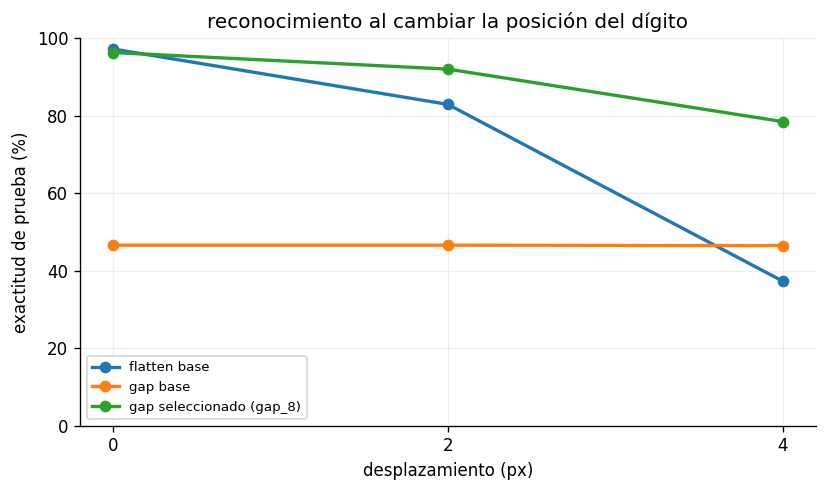

In [55]:
fig, eje = plt.subplots(figsize=(7, 4.2))
etiquetas = {"flatten_base": "flatten base", "gap_base": "gap base", nombre_elegido: f"gap seleccionado ({nombre_elegido})"}
for nombre in modelos_finales:
    valores = tabla_prueba.loc[nombre, ["0 px (%)", "2 px (%)", "4 px (%)"]].to_numpy(dtype=float)
    eje.plot([0, 2, 4], valores, marker="o", linewidth=2, label=etiquetas[nombre])
eje.set(xlabel="desplazamiento (px)", ylabel="exactitud de prueba (%)", title="reconocimiento al cambiar la posición del dígito", xticks=[0, 2, 4], ylim=(0, 100))
eje.grid(alpha=0.2)
eje.legend(fontsize=8)
fig.tight_layout()
fig.savefig(salida / "desplazamientos.png", bbox_inches="tight")
plt.show()

La ventaja frente a Flatten ya se nota a 2 px, 92.14 % frente a 82.75 %. A 4 px la diferencia es de 41.29 puntos. La curva se interpreta junto con la exactitud inicial y la tabla de caídas. El promedio global reduce la dependencia de la posición, pero los bordes y el max pooling pueden conservar cierta sensibilidad al desplazamiento.

## 12. Conclusión

El cambio más claro para alcanzar el objetivo fue agregar una quinta convolución. En el contraste gap_7 → gap_8, la validación pasó de 94.80 % a 96.13 %. El GAP base tiene pocas capas para combinar la forma de los trazos antes de promediar. Las variantes con un campo receptivo mayor y suficientes filtros logran características más útiles, cambiar Flatten por GAP sin mejorar el extractor no fue suficiente.

Me quedé con gap_8, con 96.13 % de validación y 24,714 parámetros entrenables. Frente a los 54 330 de Flatten, el ahorro es de 29,616 parámetros, equivalente al 54.51.

La ventaja frente a Flatten ya se aprecia a 2 px 92.14 % frente a 82.75 %. A 4 px la diferencia es de 41.29 puntos. El GAP seleccionado conserva 78.58 % a 4 px, con una caída de 17.83 puntos. Flatten conserva 37.29 % y cae 59.81 puntos. Por eso, en esta ejecución, el GAP seleccionado combina mejor una buena exactitud inicial con tolerancia al movimiento. El GAP base es estable, pero su exactitud final sigue siendo baja.

La selección se limita a las diez arquitecturas y a esta partición con semilla 42. Las interpretaciones numéricas describen la ejecución guardada; si se cambia la configuración y se vuelve a entrenar, deben actualizarse con los nuevos resultados.




## Referencias

- [MNIST en Keras](https://www.tensorflow.org/api_docs/python/tf/keras/datasets/mnist/load_data).
- [GlobalAveragePooling2D](https://www.tensorflow.org/api_docs/python/tf/keras/layers/GlobalAveragePooling2D).
- Notebook de la sesión `icd-21-cnn.ipynb`, proporcionado con la actividad.